# **Cifar10 CNN**


In [ ]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt


(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

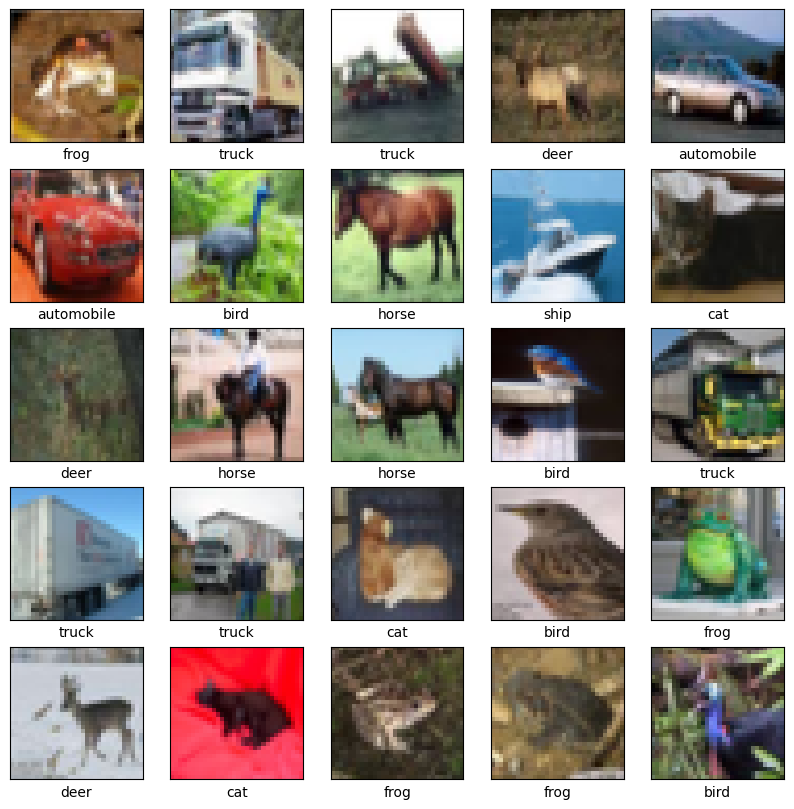

In [ ]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays,
    # which is why you need the extra index
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

In [ ]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

history = model.fit(train_images, train_labels, epochs=10,
                    validation_data=(test_images, test_labels))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 68s 42ms/step - accuracy: 0.3605 - loss: 1.7253 - val_accuracy: 0.5353 - val_loss: 1.3180
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 62s 40ms/step - accuracy: 0.5771 - loss: 1.1859 - val_accuracy: 0.6304 - val_loss: 1.0583
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 83s 40ms/step - accuracy: 0.6474 - loss: 1.0042 - val_accuracy: 0.6445 - val_loss: 1.0153
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 61s 39ms/step - accuracy: 0.6903 - loss: 0.8889 - val_accuracy: 0.6878 - val_loss: 0.8980
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 39ms/step - accuracy: 0.7191 - loss: 0.8083 - val_accuracy: 0.6810 - val_loss: 0.9355
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 61s 39ms/step - accuracy: 0.7358 - loss: 0.7488 - val_accuracy: 0.6912 - val_loss: 0.8867
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 39ms/step - accuracy: 0.7555 - loss: 0.6898 - val_accuracy: 0.6980 - val_loss: 0.8868
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 83s 40ms/step - accuracy: 0.7739 -

313/313 - 3s - 10ms/step - accuracy: 0.7153 - loss: 0.8660


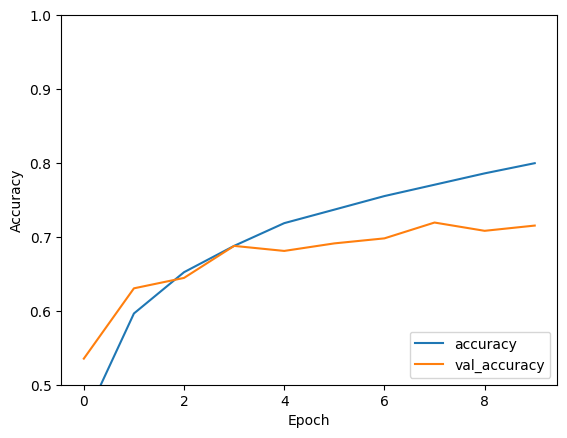

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

# **LSTM**

Sinus dalgası

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense



In [ ]:
# --- Veri üret ---
x = np.linspace(0, 100, 1000)
y = np.sin(x)

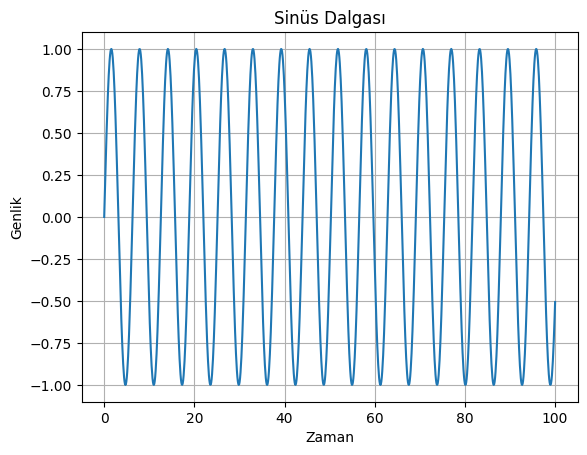

In [ ]:
plt.plot(x, y)                  # x ekseni zamana karşı sinyal
plt.title("Sinüs Dalgası")
plt.xlabel("Zaman")
plt.ylabel("Genlik")
plt.grid(True)
plt.show()

In [ ]:
# --- LSTM için sekans oluştur ---
def create_sequences(data, seq_length=50):
    X, y_out = [], []
    for i in range(len(data)-seq_length):
        X.append(data[i:i+seq_length])
        y_out.append(data[i+seq_length])
    return np.array(X), np.array(y_out)

seq_length = 50
X, y_data = create_sequences(y, seq_length)
X = X.reshape((X.shape[0], X.shape[1], 1))  # LSTM input = (örnek, zaman_adımı, özellik)

In [ ]:
# --- Model kur ---
model = Sequential()
model.add(LSTM(64, input_shape=(seq_length, 1)))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')

In [ ]:
# --- Eğit ---
model.fit(X, y_data, epochs=10, batch_size=32)

Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.3195
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0064
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 6.8955e-04
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 2.7941e-04
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 1.7012e-04
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 9.1256e-05
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 4.0272e-05
Epoch 8/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 1.3534e-05
Epoch 9/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 4.3481e-06
Epoch 10/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 1.3906e-06


30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


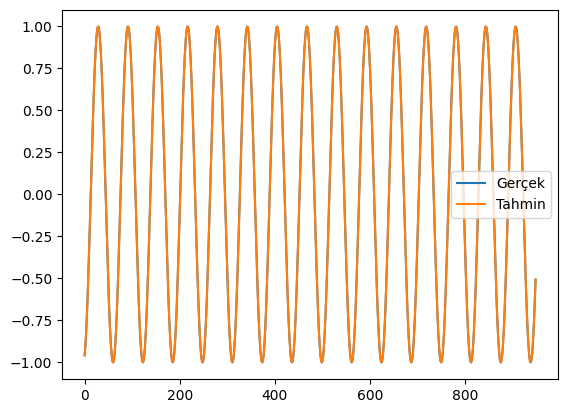

In [ ]:
# --- Tahmin ---
y_pred = model.predict(X)

plt.plot(y_data, label="Gerçek")
plt.plot(y_pred, label="Tahmin")
plt.legend()
plt.show()

Metin tahmini

In [ ]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Veri
text = "merhaba"
chars = sorted(list(set(text)))
char2idx = {c:i for i,c in enumerate(chars)}
idx2char = {i:c for i,c in enumerate(chars)}

# Karakterleri sayıya çevir
seq = [char2idx[c] for c in text]


In [ ]:
seq

[4, 2, 5, 3, 0, 1, 0]

In [ ]:
# LSTM için input-output oluştur
X, y = [], []
for i in range(len(seq)-1):
    X.append(seq[i])
    y.append(seq[i+1])

In [ ]:
X = np.array(X).reshape(-1, 1, 1)  # (örnek, zaman_adımı=1, özellik=1)
y = to_categorical(y, num_classes=len(chars))

In [ ]:
y

array([[0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1.],
       [0., 0., 0., 1., 0., 0.],
       [1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0.]])

In [ ]:
# Model
model = Sequential()
model.add(LSTM(32, input_shape=(1,1)))
model.add(Dense(len(chars), activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])


In [ ]:
model.fit(X, y, epochs=300, verbose=0)

In [ ]:
# Test: "m" -> tahmin ne?
test = np.array([[char2idx["m"]]]).reshape(1,1,1)
pred = model.predict(test)
print("Tahmin:", idx2char[np.argmax(pred)])


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 585ms/step
Tahmin: h


SİNYAL SINIFLANDIRMA (Basit gürültülü veri)

In [ ]:
# Rastgele 2 sınıflı sinyal üret
signal1 = np.sin(np.linspace(0,10,100))   # sınıf 0
signal2 = np.sin(np.linspace(0,10,100)) + 0.5*np.random.randn(100) # sınıf 1

X = np.array([signal1, signal2])
y = np.array([0,1])

X = X.reshape((2, 100, 1))  # 2 örnek, 100 zaman adımı, 1 özellik


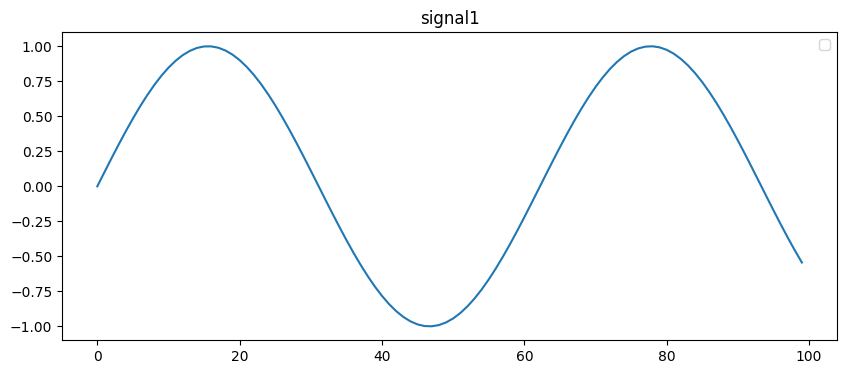

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(signal1)
plt.legend()
plt.title("signal1")
plt.show()

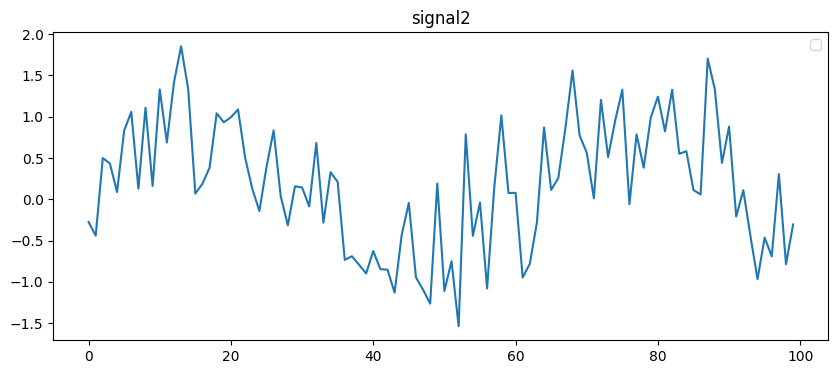

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(signal2)
plt.legend()
plt.title("signal2")
plt.show()

In [ ]:

model = Sequential()
model.add(LSTM(32, input_shape=(100,1)))
model.add(Dense(1, activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])


In [ ]:

model.fit(X, y, epochs=50, verbose=0)
print("Eğitim tamamlandı!")


Eğitim tamamlandı!


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step


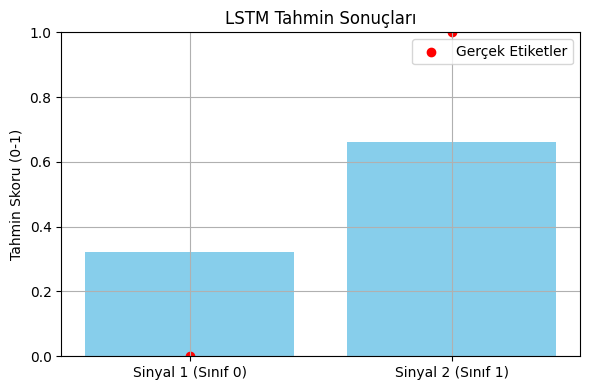

In [ ]:
# Tahmin
predictions = model.predict(X).flatten()  # (2,1) → (2,)

# Görselleştirme
plt.figure(figsize=(6, 4))
plt.bar(['Sinyal 1 (Sınıf 0)', 'Sinyal 2 (Sınıf 1)'], predictions, color='skyblue')
plt.scatter(['Sinyal 1 (Sınıf 0)', 'Sinyal 2 (Sınıf 1)'], y, color='red', label='Gerçek Etiketler')
plt.title('LSTM Tahmin Sonuçları')
plt.ylabel('Tahmin Skoru (0-1)')
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


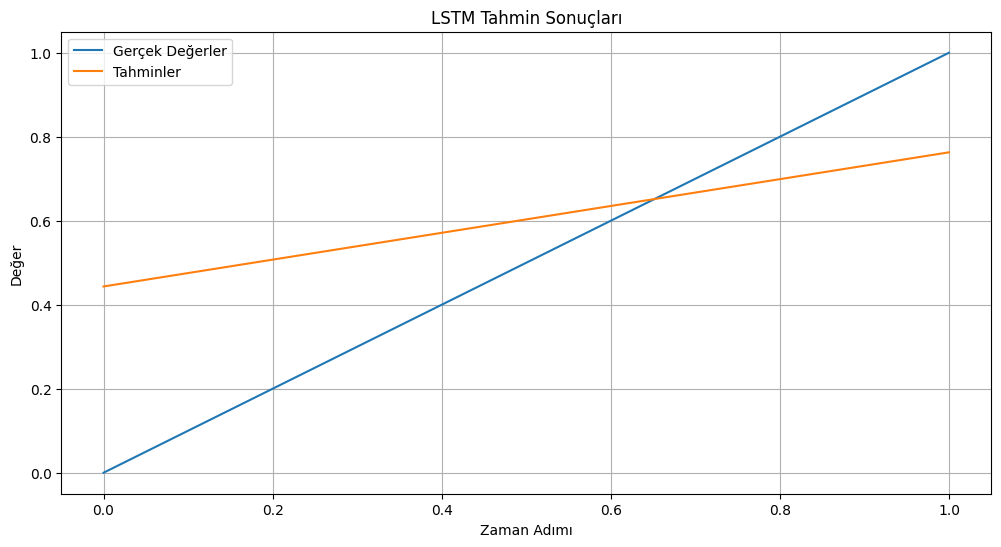

In [ ]:
predictions = model.predict(X)


plt.figure(figsize=(12, 6))
plt.plot(y, label='Gerçek Değerler')
plt.plot(predictions, label='Tahminler')
plt.title('LSTM Tahmin Sonuçları')
plt.xlabel('Zaman Adımı')
plt.ylabel('Değer')
plt.legend()
plt.grid(True)
plt.show()

# **LLM**

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import classification_report

# 1. Basit veri
corpus = [
    "merhaba nasılsın",
    "merhaba günaydın",
    "merhaba nasılsın bugün",
    "merhaba ne haber",
    "merhaba iyi misin",
    "merhaba nasılsın iyi misin"
]

# 2. Tokenizer ile kelimeleri sayıya çevir
tokenizer = Tokenizer()
tokenizer.fit_on_texts(corpus)
total_words = len(tokenizer.word_index) + 1

print("Kelime indeksi:", tokenizer.word_index)

# 3. Eğitim verisini oluştur (n-gram)
input_sequences = []
for line in corpus:
    tokens = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(tokens)):
        n_gram = tokens[:i+1]
        input_sequences.append(n_gram)

# 4. Pad et ve X, y ayır
max_seq_len = max([len(x) for x in input_sequences])
input_sequences = pad_sequences(input_sequences, maxlen=max_seq_len, padding='pre')

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

# y'yi kategorik yap
y_cat = tf.keras.utils.to_categorical(y, num_classes=total_words)



Kelime indeksi: {'merhaba': 1, 'nasılsın': 2, 'iyi': 3, 'misin': 4, 'günaydın': 5, 'bugün': 6, 'ne': 7, 'haber': 8}


In [ ]:
# 5. Model oluştur
model = Sequential()
model.add(Embedding(input_dim=total_words, output_dim=10, input_length=max_seq_len - 1))
model.add(LSTM(32))
model.add(Dense(total_words, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 6. Eğit
model.fit(X, y_cat, epochs=200, verbose=0)


In [ ]:

# 7. Test için tahmin fonksiyonu
def predict_next_word(seed_text, max_len=max_seq_len):
    token_list = tokenizer.texts_to_sequences([seed_text])[0]
    token_list = pad_sequences([token_list], maxlen=max_len-1, padding='pre')
    prediction = model.predict(token_list, verbose=0)
    predicted_index = np.argmax(prediction)
    predicted_word = tokenizer.index_word.get(predicted_index, '?')
    return predicted_word, prediction[0][predicted_index]



In [ ]:

# 8. Tahmin yapalım
test_inputs = [
    "merhaba",
    "merhaba nasılsın",
    "merhaba iyi"
]

print("\n🔍 Tahmin Sonuçları:")
y_true = []
y_pred = []




🔍 Tahmin Sonuçları:


In [ ]:
for seed in test_inputs:
    next_word, prob = predict_next_word(seed)
    print(f"\"{seed}\" ➜ Tahmin: \"{next_word}\" (%{prob*100:.1f})")

    # Karşılaştırma için gerçek varsa:
    seq = tokenizer.texts_to_sequences([seed])[0]
    full_seq = tokenizer.texts_to_sequences([s for s in corpus if s.startswith(seed)])
    if full_seq:
        gt = full_seq[0][len(seq)] if len(full_seq[0]) > len(seq) else 0
        y_true.append(gt)
        y_pred.append(tokenizer.word_index.get(next_word, 0))


"merhaba" ➜ Tahmin: "nasılsın" (%49.4)
"merhaba nasılsın" ➜ Tahmin: "iyi" (%41.7)
"merhaba iyi" ➜ Tahmin: "misin" (%72.3)


In [ ]:
# 9. Değerlendirme (isteğe bağlı)
if len(y_true) > 0:
    print("\n📊 Değerlendirme Raporu:")
    print(classification_report(y_true, y_pred, zero_division=0, target_names=list(tokenizer.word_index.keys())))


📊 Değerlendirme Raporu:
